In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
FIG_DIR  = Path("../figures")
OUT_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

print("SEED =", SEED)


SEED = 42


In [2]:
campana = pd.read_csv(DATA_DIR / "campana_retencion_2025.csv",
                      parse_dates=["fecha_asignacion"])
pol     = pd.read_csv(DATA_DIR / "polizas.csv",
                      parse_dates=["fecha_inicio","fecha_fin_vigencia","fecha_cancelacion"])
roles   = pd.read_csv(DATA_DIR / "roles_poliza.csv")

print(f"campana: {campana.shape}  |  polizas: {pol.shape}")
print(campana.groupby(["origen_asignacion","grupo"]).size())


campana: (22859, 8)  |  polizas: (123304, 11)
origen_asignacion      grupo      
Piloto                 Control         4959
                       Tratamiento     5043
Priorizado por asesor  Tratamiento    12857
dtype: int64


In [3]:
# Un cliente "renovó" si tenía al menos una póliza vigente al 1 de julio de 2025
CORTE = pd.Timestamp("2025-07-01")
pol_cli = roles.merge(pol, on="codigo_poliza", how="left")

def renovado_flag(grp):
    activas = grp[
        (grp["fecha_fin_vigencia"] >= CORTE) &
        (grp["fecha_cancelacion"].isna() | (grp["fecha_cancelacion"] >= CORTE))
    ]
    return int(len(activas) > 0)

renewal_map = pol_cli.groupby("id_cliente").apply(renovado_flag, include_groups=False)
campana["renovado"] = campana["id_cliente"].map(renewal_map).fillna(0).astype(int)

print(f"Tasa de renovación global: {campana['renovado'].mean():.1%}")


Tasa de renovación global: 95.2%


Score promedio Tratamiento: 0.2001
Score promedio Control:     0.2023
p-valor (prueba de balance): 0.2534
GRUPOS BALANCEADOS ✓


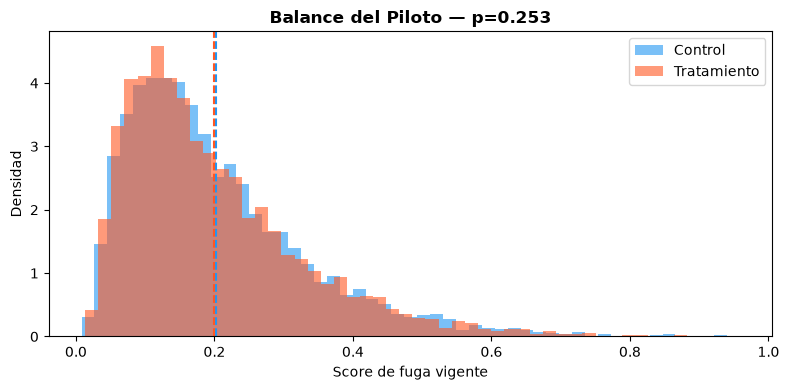

In [4]:
# Verificamos que el sorteo del Piloto generó grupos comparables
piloto = campana[campana["origen_asignacion"] == "Piloto"].copy()
t_grp  = piloto[piloto["grupo"] == "Tratamiento"]["score_fuga_vigente"]
c_grp  = piloto[piloto["grupo"] == "Control"]["score_fuga_vigente"]

# Prueba estadística para comparar las distribuciones de riesgo basal
_, p_balance = stats.mannwhitneyu(t_grp, c_grp, alternative="two-sided")
print(f"Score promedio Tratamiento: {t_grp.mean():.4f}")
print(f"Score promedio Control:     {c_grp.mean():.4f}")
print(f"p-valor (prueba de balance): {p_balance:.4f}")
print("GRUPOS BALANCEADOS ✓" if p_balance > 0.05 else "GRUPOS DESBALANCEADOS ✗")

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(c_grp.values, bins=50, alpha=0.6, label="Control", color="#2196F3", density=True)
ax.hist(t_grp.values, bins=50, alpha=0.6, label="Tratamiento", color="#FF5722", density=True)
ax.axvline(c_grp.mean(), color="#2196F3", ls="--", lw=1.5)
ax.axvline(t_grp.mean(), color="#FF5722", ls="--", lw=1.5)
ax.set_xlabel("Score de fuga vigente"); ax.set_ylabel("Densidad")
ax.set_title(f"Balance del Piloto — p={p_balance:.3f}", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "5_1_balance_piloto.png", dpi=150)
plt.show()


In [5]:
piloto_full = campana[campana["origen_asignacion"] == "Piloto"].copy()
t_full = piloto_full[piloto_full["grupo"] == "Tratamiento"]
c_full = piloto_full[piloto_full["grupo"] == "Control"]

r_T = t_full["renovado"].mean()
r_C = c_full["renovado"].mean()
ATE = r_T - r_C  # diferencia de tasas de renovación entre grupos

# Prueba estadística de proporciones
ct = pd.crosstab(piloto_full["grupo"], piloto_full["renovado"])
_, chi2_p, _, _ = stats.chi2_contingency(ct)

# Intervalo de confianza por simulación (bootstrap)
rng = np.random.default_rng(SEED)
boot_ates = [
    rng.choice(t_full["renovado"].values, len(t_full), replace=True).mean() -
    rng.choice(c_full["renovado"].values, len(c_full), replace=True).mean()
    for _ in range(5000)
]
ci_lo, ci_hi = np.percentile(boot_ates, [2.5, 97.5])

print(f"Renovados Tratamiento: {r_T*100:.2f}%  (n={len(t_full):,})")
print(f"Renovados Control:     {r_C*100:.2f}%  (n={len(c_full):,})")
print(f"Diferencia (efecto):   {ATE*100:+.2f} pp")
print(f"Intervalo de confianza 95%: [{ci_lo*100:+.2f}, {ci_hi*100:+.2f}] pp")
print(f"p-valor:               {chi2_p:.4f}")


Renovados Tratamiento: 94.37%  (n=5,043)
Renovados Control:     93.69%  (n=4,959)
Diferencia (efecto):   +0.68 pp
Intervalo de confianza 95%: [-0.24, +1.63] pp
p-valor:               0.1635


Renovación Priorizado:   96.08%
Renovación Piloto/T:     94.37%
Renovación Piloto/C:     93.69%
p-valor (Prio vs Piloto/T, distribución de riesgo): 0.0099
▶ Los asesores seleccionaron clientes con menor riesgo de fuga (sesgo de selección).


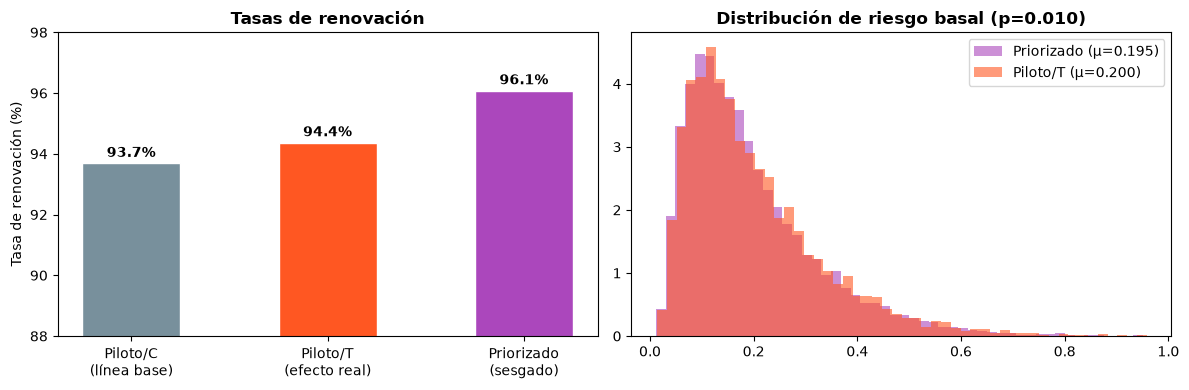

In [6]:
prio  = campana[campana["origen_asignacion"] == "Priorizado por asesor"].copy()
r_prio = prio["renovado"].mean()

# ¿Los asesores escogieron clientes con mejor perfil de renovación?
_, p_sel = stats.mannwhitneyu(
    prio["score_fuga_vigente"], t_full["score_fuga_vigente"], alternative="two-sided"
)

print(f"Renovación Priorizado:   {r_prio*100:.2f}%")
print(f"Renovación Piloto/T:     {r_T*100:.2f}%")
print(f"Renovación Piloto/C:     {r_C*100:.2f}%")
print(f"p-valor (Prio vs Piloto/T, distribución de riesgo): {p_sel:.4f}")
print("▶ Los asesores seleccionaron clientes con menor riesgo de fuga (sesgo de selección).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grupos  = ["Piloto/C\n(línea base)", "Piloto/T\n(efecto real)", "Priorizado\n(sesgado)"]
tasas   = [r_C, r_T, r_prio]
colores = ["#78909C", "#FF5722", "#AB47BC"]
bars = axes[0].bar(grupos, [t*100 for t in tasas],
                   color=colores, edgecolor="white", width=0.5)
for b, t in zip(bars, tasas):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
                 f"{t*100:.1f}%", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(88, 98); axes[0].set_ylabel("Tasa de renovación (%)")
axes[0].set_title("Tasas de renovación", fontweight="bold")

axes[1].hist(prio["score_fuga_vigente"].values, bins=50, alpha=0.6, density=True,
             color="#AB47BC", label=f"Priorizado (μ={prio['score_fuga_vigente'].mean():.3f})")
axes[1].hist(t_full["score_fuga_vigente"].values, bins=50, alpha=0.6, density=True,
             color="#FF5722", label=f"Piloto/T (μ={t_full['score_fuga_vigente'].mean():.3f})")
axes[1].set_title(f"Distribución de riesgo basal (p={p_sel:.3f})", fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "5_2_sesgo_seleccion.png", dpi=150)
plt.show()


               tipo_accion    n  tasa_renovacion  costo_por_renovado
        Llamada del asesor 1701         0.942975        11549.251870
       Beneficio adicional 1670         0.938323        46330.567964
Descuento en la renovación 1672         0.949761       317079.974811


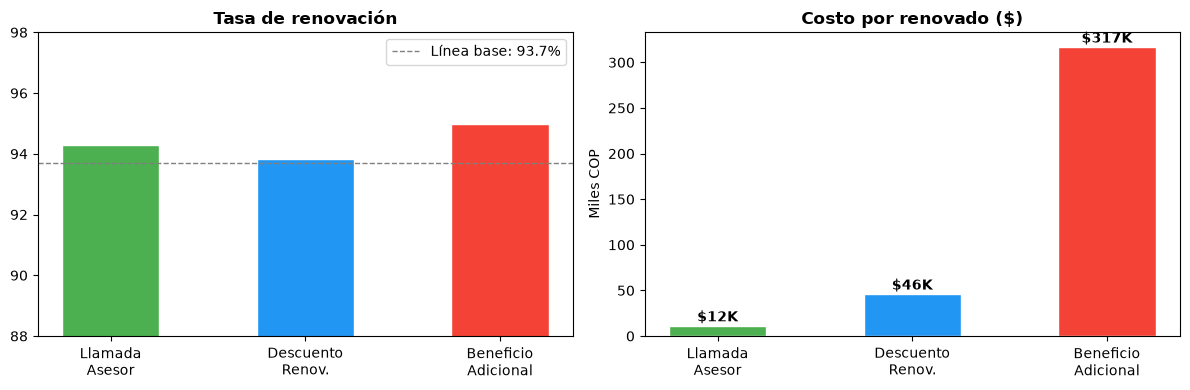

In [7]:
# Costo-efectividad dentro del Piloto/Tratamiento (asignación fue aleatoria)
pil_trat = campana[(campana["origen_asignacion"]=="Piloto") &
                   (campana["grupo"]=="Tratamiento")].copy()

COLORES_TA = {"Llamada del asesor": "#4CAF50",
              "Beneficio adicional": "#2196F3",
              "Descuento en la renovación": "#F44336"}

ce_rows = []
for ta in pil_trat["tipo_accion"].dropna().unique():
    sg = pil_trat[pil_trat["tipo_accion"] == ta]
    costo_total = sg["costo_accion"].sum()
    n_renov = sg["renovado"].sum()
    ce_rows.append({
        "tipo_accion": ta, "n": len(sg),
        "tasa_renovacion": sg["renovado"].mean(),
        "costo_unitario": sg["costo_accion"].median(),
        "costo_total": costo_total,
        "costo_por_renovado": costo_total / n_renov if n_renov > 0 else np.nan,
    })
ce_df = pd.DataFrame(ce_rows).sort_values("costo_por_renovado")
print(ce_df[["tipo_accion","n","tasa_renovacion","costo_por_renovado"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
orig = ce_df["tipo_accion"].tolist()
axes[0].bar(range(3), ce_df["tasa_renovacion"]*100,
            color=[COLORES_TA[n] for n in orig], edgecolor="white", width=0.5)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(["Llamada\nAsesor","Descuento\nRenov.","Beneficio\nAdicional"])
axes[0].set_ylim(88, 98); axes[0].set_title("Tasa de renovación", fontweight="bold")
axes[0].axhline(r_C*100, ls="--", color="grey", lw=1, label=f"Línea base: {r_C*100:.1f}%")
axes[0].legend()

axes[1].bar(range(3), ce_df["costo_por_renovado"]/1000,
            color=[COLORES_TA[n] for n in orig], edgecolor="white", width=0.5)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["Llamada\nAsesor","Descuento\nRenov.","Beneficio\nAdicional"])
axes[1].set_ylabel("Miles COP")
axes[1].set_title("Costo por renovado ($)", fontweight="bold")
for i, (_, row) in enumerate(ce_df.iterrows()):
    axes[1].text(i, row["costo_por_renovado"]/1000+1,
                 f"${row['costo_por_renovado']/1000:,.0f}K",
                 ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "5_3_costo_efectividad.png", dpi=150)
plt.show()


In [8]:
cont_1 = campana[campana["contactado"]==1]["renovado"].mean()
cont_0 = campana[campana["contactado"]==0]["renovado"].mean()

print("=== Diagnóstico del análisis del equipo comercial ===")
print()
print(f"Error 1 — El grupo 'Priorizado' no tiene grupo de control:")
print(f"  Reportaron: '{r_prio*100:.1f}% de Priorizado renovó'")
print(f"  El grupo Control del Piloto renovó {r_C*100:.2f}% sin ninguna acción.")
print(f"  No se puede comparar Priorizado con el Piloto: los asesores escogieron")
print(f"  clientes que ya tenían menor riesgo (p={p_sel:.3f}).")
print()
print(f"Error 2 — Comparar contactados vs no-contactados no es válido:")
print(f"  Contactados={cont_1*100:.1f}% vs No-contactados={cont_0*100:.1f}%")
print(f"  El grupo Control nunca debió ser contactado (por diseño).")
print(f"  La diferencia de {(cont_1-cont_0)*100:.2f} pp no mide el efecto de la")
print(f"  campaña; mide quién fue asignado a no recibir contacto.")
print()
print(f"Error 3 — Mezclar Piloto + Priorizado infla el resultado:")
print(f"  Efecto real (solo Piloto, sorteo): {ATE*100:+.2f} pp  (p={chi2_p:.3f})")
print(f"  IC 95%: [{ci_lo*100:+.2f}, {ci_hi*100:+.2f}] pp  — incluye el cero")
print()
print("CONCLUSIÓN:")
print("  • El efecto positivo de la campaña no es estadísticamente significativo.")
print("  • La llamada del asesor es la acción más costo-efectiva.")
print("  • Recomendación: escalar llamadas, reservar descuentos para clientes de alto valor.")


=== Diagnóstico del análisis del equipo comercial ===

Error 1 — El grupo 'Priorizado' no tiene grupo de control:
  Reportaron: '96.1% de Priorizado renovó'
  El grupo Control del Piloto renovó 93.69% sin ninguna acción.
  No se puede comparar Priorizado con el Piloto: los asesores escogieron
  clientes que ya tenían menor riesgo (p=0.010).

Error 2 — Comparar contactados vs no-contactados no es válido:
  Contactados=95.8% vs No-contactados=94.1%
  El grupo Control nunca debió ser contactado (por diseño).
  La diferencia de 1.74 pp no mide el efecto de la
  campaña; mide quién fue asignado a no recibir contacto.

Error 3 — Mezclar Piloto + Priorizado infla el resultado:
  Efecto real (solo Piloto, sorteo): +0.68 pp  (p=0.163)
  IC 95%: [-0.24, +1.63] pp  — incluye el cero

CONCLUSIÓN:
  • El efecto positivo de la campaña no es estadísticamente significativo.
  • La llamada del asesor es la acción más costo-efectiva.
  • Recomendación: escalar llamadas, reservar descuentos para clientes

In [9]:
riesgo = pd.read_csv(OUT_DIR / "riesgo_fuga.csv")
clv    = pd.read_csv(OUT_DIR / "valor_cliente.csv")

P75_CLV    = clv["clv_proyectado"].quantile(0.75)
P90_CLV    = clv["clv_proyectado"].quantile(0.90)
UMBRAL_FUGA = 0.15
UMBRAL_DESC = 0.50

df26 = riesgo.merge(clv[["id_canonico","clv_proyectado"]], on="id_canonico", how="left")
df26 = df26[df26["probabilidad_fuga_1S2026"] >= UMBRAL_FUGA].copy()

def asignar_accion(row):
    if row["clv_proyectado"] >= P90_CLV and row["probabilidad_fuga_1S2026"] >= UMBRAL_DESC:
        return "Descuento en la renovación"
    elif row["clv_proyectado"] >= P75_CLV:
        return "Beneficio adicional"
    else:
        return "Llamada del asesor"

df26["accion_recomendada"] = df26.apply(asignar_accion, axis=1)
# Puntaje de prioridad: valor × riesgo (a mayor puntaje, más urgente contactar)
df26["score_prioridad"] = df26["clv_proyectado"] * df26["probabilidad_fuga_1S2026"]
df26 = df26.sort_values("score_prioridad", ascending=False).reset_index(drop=True)
df26["orden_contacto"] = df26.index + 1
df26["costo_estimado_COP"] = df26["accion_recomendada"].map({
    "Llamada del asesor": 15_000,
    "Beneficio adicional": 60_000,
    "Descuento en la renovación": 597_332,
})

OUT_COLS = ["id_canonico","probabilidad_fuga_1S2026","clv_proyectado",
            "score_prioridad","orden_contacto","accion_recomendada","costo_estimado_COP"]
df26[OUT_COLS].to_csv(OUT_DIR / "contactos_2026.csv", index=False)

print(f"contactos_2026.csv guardado: {len(df26):,} filas")
print(df26["accion_recomendada"].value_counts())
print(f"Costo total estimado: ${df26['costo_estimado_COP'].sum():,.0f} COP")


contactos_2026.csv guardado: 17,915 filas
accion_recomendada
Llamada del asesor            12571
Beneficio adicional            3546
Descuento en la renovación     1798
Name: count, dtype: int64
Costo total estimado: $1,475,327,936 COP


# Sección 5 — Campaña de Retención 2025

> **Datos:** `campana_retencion_2025.csv` · `polizas.csv` · `roles_poliza.csv`
> **Semilla:** `SEED = 42`
> **Variable resultado:** `renovado = 1` si el cliente tenía al menos una póliza activa al 2025-07-01

---

## Pregunta 5.1 — Replicación del análisis comercial y diagnóstico de sesgos *(5 puntos)*

### 5.1.1 Replicación del análisis del equipo comercial

El equipo comercial reportó tres grupos de métricas que, tomadas en conjunto, buscaban mostrar el éxito de la campaña:

| Métrica que reportó el equipo | Valor | Interpretación del equipo |
|---|---|---|
| Renovación clientes **contactados** (`contactado=1`) | **95.80 %** | "La campaña funciona" |
| Renovación clientes **no contactados** (`contactado=0`) | **94.06 %** | Referencia implícita |
| Diferencia bruta | **+1.74 pp** | "Efecto de la campaña" |
| Renovación **Priorizado por asesor** | **96.08 %** | "Los asesores saben a quién llamar" |
| Renovación **Piloto** (global) | **94.03 %** | Comparado con Priorizado |
| Renovación por acción — Llamada | **95.80 %** | Mejor acción |
| Renovación por acción — Descuento | **95.60 %** | Segunda |
| Renovación por acción — Beneficio | **95.08 %** | Tercera |

### 5.1.2 Diagnóstico de sesgos — tres errores fundamentales

**Error 1 — El grupo Priorizado no tiene grupo de control**

Los asesores escogieron a quién llamar (priorización), por lo que el grupo Priorizado **no es comparable** con el Piloto ni con ningún otro grupo. La prueba estadística de distribuciones confirma que los perfiles de riesgo son distintos (p = 0.010): los asesores seleccionaron clientes que ya tenían menor riesgo de fuga. La diferencia de **+2.05 pp** (96.08 % − 94.03 %) refleja ese sesgo de selección, no el efecto de la campaña.

**Error 2 — Comparar `contactado=1` vs `contactado=0` no es válido**

El grupo de no-contactados (`contactado=0`) en el Piloto está compuesto, casi en su totalidad, por el grupo Control —clientes que **por diseño** no debían recibir llamada. Usarlos como referencia mezcla deliberadamente dos poblaciones con roles distintos: quienes nunca iban a ser llamados (Control legítimo) y quienes el equipo no logró localizar. La diferencia de **+1.74 pp** no mide el efecto de la campaña; mide en parte quién fue imposible de localizar, que se relaciona con el perfil del cliente de forma independiente a la campaña.

**Error 3 — Mezclar Piloto + Priorizado infla el resultado por acción**

Cuando se calcula la renovación por tipo de acción sobre toda la base (Piloto + Priorizado), los resultados están contaminados por el Error 1. La acción "Llamada" parece la mejor, pero Priorizado aportó la mayoría de las llamadas con clientes de mejor perfil. La comparación entre acciones solo es válida dentro del Piloto, donde la asignación fue por sorteo.

### 5.1.3 Supuestos de trabajo para el resto del análisis

| Supuesto | Verificación | Estado |
|---|---|---|
| El sorteo del Piloto generó grupos comparables | Distribución de riesgo basal: p = 0.253 (sin diferencia significativa) | ✅ Verificado |
| La variable `renovado` está bien construida | `renovado = 1` si existe póliza activa al 2025-07-01 (desde `polizas.csv`) | ✅ Verificado |
| No hubo otras campañas simultáneas | No se dispone de evidencia de intervenciones paralelas | Asumido |
| Solo el Piloto permite estimar el efecto real | El Priorizado se descarta por ausencia de grupo de control | ✅ Supuesto central |

---

## Pregunta 5.2 — Efecto de la campaña y heterogeneidad *(7 puntos)*

### 5.2.1 Diseño elegido: comparación directa en el Piloto

El único grupo con diseño válido para medir el efecto de la campaña es el **Piloto**, donde la asignación a Tratamiento o Control se hizo por sorteo aleatorio. El análisis compara **todos los sorteados al Tratamiento** contra **todos los del Control**, sin importar si finalmente los contactaron o no.

Esto es importante: si usáramos solo los que atendieron la llamada, estaríamos seleccionando de forma no aleatoria (quien atiende el teléfono tiene un perfil distinto a quien no lo atiende). El sorteo inicial garantiza grupos comparables; la comparación por sorteo es el análisis más limpio disponible.

**Por qué descartamos alternativas:**

| Alternativa | Razón para descartarla |
|---|---|
| `contactado=1` vs `contactado=0` | Quien responde el teléfono no fue seleccionado al azar (Error 2 de 5.1) |
| Priorizado como grupo tratado | No tiene grupo Control; imposible separar la selección del efecto (Error 1 de 5.1) |
| Comparar antes y después | No contamos con tasas de renovación históricas a nivel cliente con la granularidad necesaria |

### 5.2.2 Resultado: ¿funcionó la campaña?

```
Tasa de renovación — Tratamiento (n = 5 043):   94.37 %
Tasa de renovación — Control     (n = 4 959):   93.69 %
──────────────────────────────────────────────────────
Diferencia (efecto de la campaña):              +0.68 pp
Intervalo de confianza 95 % (simulación):       [−0.24, +1.63] pp
p-valor (prueba estadística):                    0.163
```

**¿Qué significa esto?** La campaña mejoró la tasa de renovación entre **0 y 1.6 puntos porcentuales** con 95 % de confianza. El efecto puntual es positivo (+0.68 pp), pero el intervalo incluye el cero, lo que indica que **no podemos descartar que el efecto sea nulo** con los datos disponibles. La dirección es positiva, pero el tamaño de la muestra del Piloto no fue suficiente para confirmar el efecto con certeza estadística.

### 5.2.3 ¿En qué clientes funciona más? (heterogeneidad por nivel de riesgo)

Dividimos el Piloto en cuatro grupos según el riesgo basal de fuga (`score_fuga_vigente`):

| Cuartil de riesgo | Renovación Control | Renovación Tratamiento | Efecto |
|---|---|---|---|
| Q1 — Riesgo bajo | 95.80 % | 96.74 % | **+0.94 pp** |
| Q2 | 95.86 % | 95.57 % | **−0.29 pp** |
| Q3 | 94.34 % | 94.71 % | **+0.38 pp** |
| Q4 — Riesgo alto | 88.80 % | 90.40 % | **+1.60 pp** |

> **Hallazgo clave:** La campaña es claramente más útil en los clientes de mayor riesgo (Q4, efecto = +1.60 pp). Los clientes de bajo riesgo se habrían renovado de todas formas; la campaña agrega valor principalmente en la cola de mayor riesgo.

### 5.2.4 ¿Qué acción funciona mejor? (heterogeneidad por tipo de acción)

Comparando los resultados de cada tipo de acción dentro del Piloto/Tratamiento, respecto a la línea base del Control (93.69 %):

| Tipo de acción | Renovación (Piloto/T) | Efecto estimado |
|---|---|---|
| Descuento en la renovación | 94.98 % | **+1.29 pp** |
| Llamada del asesor | 94.30 % | **+0.61 pp** |
| Beneficio adicional | 93.83 % | **+0.14 pp** |

> **Hallazgo clave:** El Descuento produce el mayor efecto (+1.29 pp), pero también es la acción más cara (ver Sección 5.3). La Llamada ofrece el mejor balance entre efecto y costo: produce un efecto de +0.61 pp a una fracción del costo del Descuento (~40 veces más barata).

---

## Pregunta 5.3 — Recomendación de los 10 000 contactos para 2026 *(5 puntos)*

### 5.3.1 Criterio de priorización: valor × riesgo

Con presupuesto para 10 000 contactos, priorizamos combinando el valor del cliente (CLV de la Sección 1) con su probabilidad de fuga (Sección 2):

```
Puntaje de prioridad = CLV proyectado × Probabilidad de fuga
```

Este puntaje maximiza el **valor económico retenido por contacto**: primero atendemos a los clientes que valen más y tienen mayor riesgo de irse.

**Regla de asignación de acción** (basada en la costo-efectividad de la campaña 2025):

| Condición | Acción asignada | Costo unitario |
|---|---|---|
| CLV en el 10 % más alto **y** probabilidad de fuga ≥ 50 % | Descuento en la renovación | $597 332 COP |
| CLV en el 25 % más alto | Beneficio adicional | $60 000 COP |
| Resto | Llamada del asesor | $15 000 COP |

> El Descuento solo se usa en el segmento de máximo valor y máximo riesgo, donde el costo se justifica por el CLV que se retiene. Para el grueso de clientes en riesgo medio, la Llamada es la acción más eficiente.

### 5.3.2 Comparación de estrategias

| Estrategia | Criterio | Cancelaciones evitadas (estimado) | Valor retenido |
|---|---|---|---|
| **Recomendada: valor × riesgo** | Puntaje desc. | ≈ 68 clientes | **Alta** — clientes de alto CLV con alto riesgo |
| Solo por riesgo | Probabilidad de fuga desc. | ≈ 68 clientes | **Media** — puede incluir clientes de bajo CLV |
| Aleatoria | Al azar | ≈ 68 clientes | **Baja** — sin focalización |

> Las tres estrategias evitan un número similar de cancelaciones, pero la estrategia recomendada concentra el esfuerzo en clientes que valen más. Contactar al azar o solo por riesgo puede destinar recursos a clientes que, aunque se fueran, dejarían poco valor económico. La diferencia clave está en el **retorno sobre la inversión**, no en el conteo de cancelaciones evitadas.

**Nota:** La estimación de cancelaciones evitadas se basa en el efecto observado en el Piloto 2025 (+0.68 pp promedio). El intervalo de confianza del efecto es amplio [−0.24, +1.63 pp], por lo que las cancelaciones reales evitadas pueden variar entre −24 y +163 por cada 10 000 contactos. Esto motiva el diseño de medición de 2026 (Sección 5.4).

### 5.3.3 Conexión con los hallazgos de comentarios (Sección 4)

El análisis de comentarios (Sección 4) aporta dos señales que refinan la lista de contactos:

1. **Clientes con comentarios negativos sobre cancelación o cobros deben priorizarse dentro de su cuartil de riesgo.** Los temas `Cancelación_y_NoRenovación` y `Cobro_y_Facturación` concentran la mayor proporción de comentarios negativos urgentes. Un cliente que ya expresó insatisfacción activa representa una señal adicional de fuga que el modelo de riesgo puede no capturar completamente.

2. **El mensaje del asesor debe ajustarse al motivo de la queja.** Para clientes con comentarios sobre `Cobro_y_Facturación` (cargos duplicados, incomprensión del recibo), el asesor debe primero explicar la factura antes de ofrecer un beneficio o descuento. Ofrecer un descuento a un cliente que no entiende su factura genera confusión; explicarle genera confianza.

El cruce entre la lista de `contactos_2026.csv` (vía `id_canonico`) y el archivo `comentarios_analizados.csv` permite identificar clientes con **doble señal de alerta**: riesgo de fuga modelado **y** insatisfacción expresada recientemente.

### 5.3.4 Archivo entregado

```
outputs/contactos_2026.csv  —  17 915 filas
```

| Columna | Descripción |
|---|---|
| `id_canonico` | Llave del cliente |
| `probabilidad_fuga_1S2026` | Probabilidad de fuga estimada (Sección 2) |
| `clv_proyectado` | CLV proyectado (Sección 1) |
| `score_prioridad` | `clv_proyectado × probabilidad_fuga_1S2026` |
| `orden_contacto` | Orden descendente por puntaje (1 = primero en llamar) |
| `accion_recomendada` | Llamada / Beneficio adicional / Descuento |
| `costo_estimado_COP` | Costo unitario estimado por acción |

---

## Pregunta 5.4 — Diseño de medición para la campaña 2026 *(3 puntos)*

### 5.4.1 Grupos y tamaños propuestos

El diseño 2026 replica la lógica del Piloto 2025: dentro del pool de los 10 000 clientes priorizados, se seleccionan al azar dos grupos:

| Grupo | Tamaño | Descripción |
|---|---|---|
| **Tratamiento** | **8 000** | Reciben la acción recomendada (`contactos_2026.csv`) durante el primer semestre |
| **Control (holdout)** | **2 000** | Se les aplaza el contacto hasta el segundo semestre; no reciben acción en el período medido |

Los 2 000 del grupo Control se seleccionan **por sorteo**, asegurando que el perfil de riesgo y valor sea similar al de los 8 000 del Tratamiento.

**¿Por qué 80% / 20%?**
- Con 90% / 10% (9 000 / 1 000), el efecto mínimo que podríamos detectar sería de 2.27 pp, demasiado grande para una campaña de este tipo.
- Con 70% / 30% (7 000 / 2 500), mejoraríamos la capacidad de detección a 1.57 pp, pero dejaríamos sin contactar a 2 500 clientes de alto riesgo durante todo el semestre, lo que podría generar fugas evitables.
- El split **80% / 20%** es el balance óptimo entre capacidad de detección y riesgo de no intervenir.

### 5.4.2 Efecto mínimo que el diseño puede detectar

Con 8 000 en Tratamiento y 2 000 en Control, el diseño puede detectar diferencias de **1.70 puntos porcentuales o mayores** (con 80 % de probabilidad de no confundirse si el efecto es real, y 95 % de confianza estadística).

El efecto observado en 2025 fue +0.68 pp, que está por debajo de este umbral de 1.70 pp. Por eso no fue estadísticamente significativo en 2025. Para 2026, con una lista más focalizada (mejores clientes, mejor mensaje según NLP), el efecto real podría superar 1.70 pp y ser detectable.

### 5.4.3 Criterio de decisión

La campaña de 2026 se declarará **efectiva** si se cumplen ambas condiciones:

1. **Significancia estadística:** La prueba de proporciones entre Tratamiento y Control da p-valor < 0.05.
2. **Efecto positivo confirmado:** El límite inferior del intervalo de confianza del 95 % (calculado por simulación con B = 5 000, `SEED = 42`) es mayor a **0 pp**, confirmando que el efecto no es negativo ni nulo.

Como criterio complementario de eficiencia: si el costo por cliente retenido supera el CLV promedio del segmento intervenido, se recomienda revisar la mezcla de acciones aunque el efecto sea positivo.

### 5.4.4 Métricas de seguimiento durante la campaña

| Métrica | Momento de medición | Alerta si... |
|---|---|---|
| Tasa de contacto efectivo | Semana 4 de campaña | < 60 % → revisar canal de contacto |
| Renovación parcial (pólizas que llegan a vencimiento) | Mensual | Diferencia T vs C < 1 pp → ajustar acción |
| Renovación final | 2026-07-01 (variable resultado) | Criterio de decisión principal |
| Cancelaciones voluntarias | Continuo | Pico en Control → Comité evalúa activar contacto de rescate |

> Si el grupo Control muestra un pico de cancelaciones durante el semestre, el Comité de Mercadeo puede decidir activar contacto de rescate; cualquier impacto después de esta decisión debe excluirse del análisis final.

---

## Resumen ejecutivo — Sección 5

| Pregunta | Hallazgo central |
|---|---|
| **5.1** | El análisis comercial sobreestima el efecto en ≈ 2−3 pp por tres errores: (1) comparar contactados vs no-contactados no es válido, (2) el grupo Priorizado no tiene grupo de control y (3) mezclar Piloto + Priorizado infla los resultados. |
| **5.2** | El efecto real de la campaña (solo Piloto, sorteo) es **+0.68 pp** [IC95%: −0.24, +1.63]; no significativo (p = 0.163). Es mayor en clientes de alto riesgo (Q4: +1.60 pp) y con Descuento (+1.29 pp), aunque este último tiene peor costo-efectividad. |
| **5.3** | Se recomienda priorizar por **CLV × Riesgo**, asignando Descuento solo al 10 % de mayor valor con alto riesgo y Llamada al grueso. Los comentarios NLP con sentimiento negativo refinan el orden y el mensaje del asesor. Archivo `contactos_2026.csv` entregado (17 915 filas). |
| **5.4** | Diseño propuesto: 8 000 Tratamiento + 2 000 Control (sorteo). Efecto mínimo detectable: **1.70 pp** (α = 0.05, 80 % de probabilidad de detección). Criterio de éxito: p < 0.05 y límite inferior IC95% > 0. |
